# AP 155 Lab Exercise
---
## Exercise 8: Minimization

_Instructions_: 
- **Report figure:** A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm.  
- **Report discussion:** What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Camello, Zack Kenshin)_: 
- _Student No._: 2024-08825
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure |  <span style="color:red"> 20 </span> | 20 |
| Report discussion |  <span style="color:red"> 20 </span> | 20|
| Code readability |  <span style="color:red"> 20 </span> | 20 |
| Code efficiency |  <span style="color:red"> 20 </span> | 20 | 
| Code appropriateness  |  <span style="color:red"> 20 </span> | 20 | 
| **TOTAL** |  <span style="color:red"> 100 </span> | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):  <span style="color:red"> 10/23/2026 </span>

---
## Section 1: Report

### Report figure

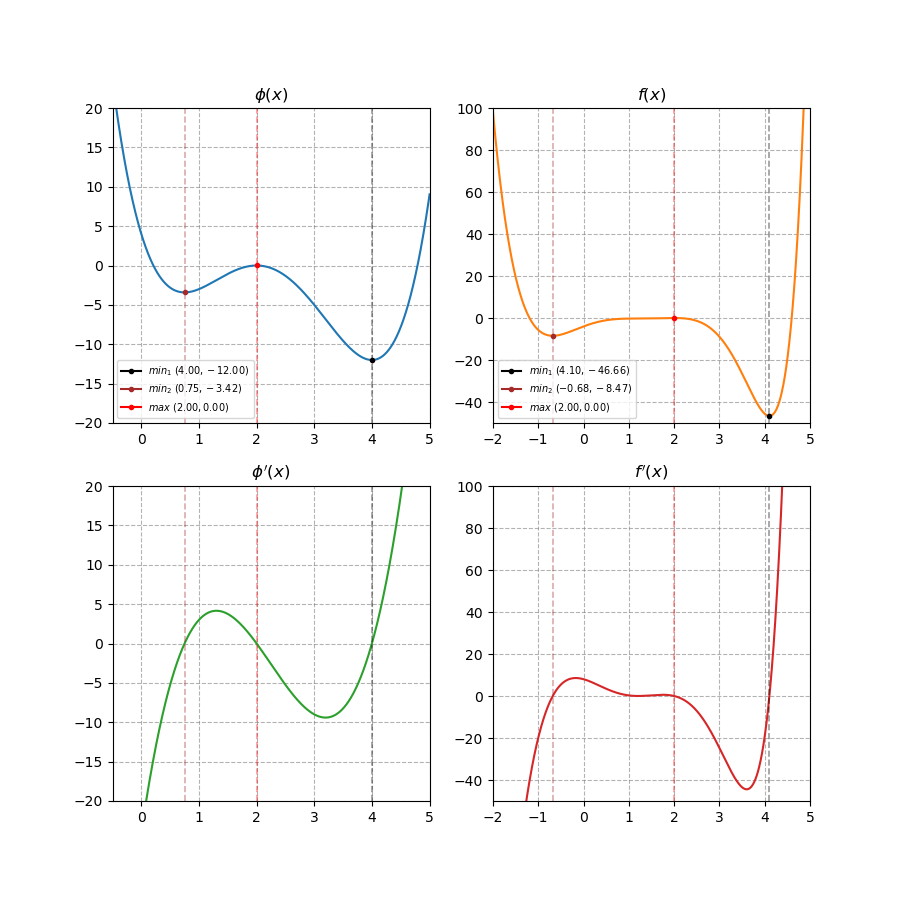

### Report discussion

What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?
- By setting our distances based on the golden ratio, when one side of the interval is dropped, the remaining internal point naturally falls in the exact spot required to serve as one of the next two test points for the next iteration while ensuring all scenarios result into the same width of interval. However, if a different value is used in the algorithm, the interval reduction is no longer guaranteed to result in an interval of the same length across both scenarios. A certain scenario could end up barely reducing the interval while another reduces it greatly, causing the search process to be both inconsistent and inefficient.

### Other comments

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Minimization

Consider the following equations:

Eq. 5.91
$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4
$$

Eq. 5.145
$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8
$$


1. Plot each of the functions. Get a rough estimate of the local minima and maxima
2. Implement 5.5.2.2 (golden section search), then determine the local minima and maxima of Eq. 5.91 and Eq. 5.145.
3. Report figure: A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm. 

In [2]:
x = np.linspace(-6, 10, 5000)
phi = (1 + np.sqrt(5))/2
N = 10000

def func_phi(x):
    return (x ** 4) - (9 * (x ** 3)) + (25 * (x ** 2)) - (24 * x) + 4

def func_phi_deriv(x):
    return (4 * (x ** 3)) - (27 * (x ** 2)) + (50 * x) - 24

def neg_phi(x):
    return -func_phi(x)

def func(x):
    return (-(x ** 5) + (4 * (x ** 4)) - (4 * (x ** 3)) + ((x ** 2)*(np.e ** x)) - 
            (2 * (x ** 2)) - (4 * x * (np.e ** x)) + (8 * x) + (4 * (np.e ** x)) - 8)

def func_deriv(x): 
    return ((-5 * (x ** 4)) + (16 * (x ** 3)) + (-12 * (x ** 2)) + - (4 * x) + 8 - (2 * x * (np.e ** x)) + ((x ** 2) * (np.e ** x)))

def neg_func(x):
    return -func(x) # For calculating the maxima (flipping the function turns our maximas into minimas which can be found by the golden-section search method)
    
def midpoint(x0, x1):
    x2 = x0 + ((x1 - x0)/(phi + 1)) # From the formula given in Gezerlis, the x2 and x3 formulas
    x3 = x0 + (((x1 - x0) * phi)/(phi + 1))

    return x2, x3

def golden(f, x0, x1, tolerance):
    # golden_hist = []
    for i in range(N):
        x2, x3 = midpoint(x0, x1)

        # Depending on whether this is true or false, the bounds of the algorithm get shifted towards the interval containing the extrema
        if f(x3) < f(x2): 
            x0 = x2    
        else:
            x1 = x3
            
        xnew = (x0 + x1) / 2
        xdiff = abs(x1 - x0)
        
        # golden_hist.append(xnew) [in case we want to see how the extremas are calculated thru time
        
        if abs(xdiff) < tolerance: # Simply stops the algorithm once our desired tolerance is reached
            break
        else:
            continue
    return xnew

In [3]:
tolerance = 1e-12

phi_guess1 = [2, 4.5]
phi_guess2 = [-0.5, 1]
phi_guess3 = [1, 3]

func_guess1 = [2, 4.5]
func_guess2 = [-2, 0]
func_guess3 = [0, 4]

phi_min1 = golden(func_phi, *phi_guess1, tolerance)
phi_min2 = golden(func_phi, *phi_guess2, tolerance)
phi_max = golden(neg_phi, *phi_guess3, tolerance)
print(phi_min1, phi_min2, phi_max)

func_min1 = golden(func, *func_guess1, tolerance)
func_min2 = golden(func, *func_guess2, tolerance)
func_max = golden(neg_func, *func_guess3, tolerance)
print(func_min1, func_min2, func_max)

3.99999997358183 0.7499999930982965 1.9999999836636628
4.103324869293454 -0.6798620168422456 1.999999950819668


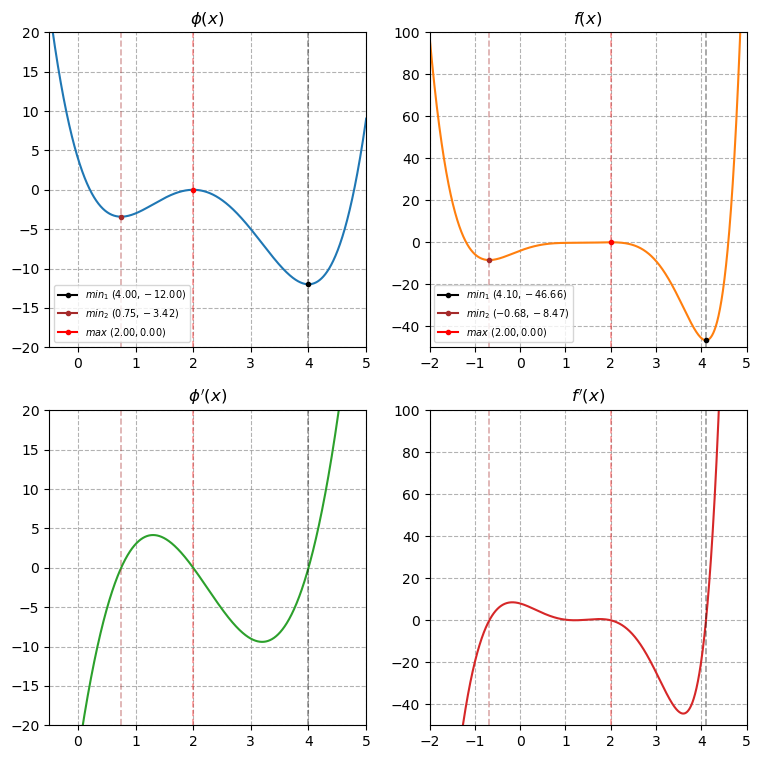

In [4]:
fig, axs = plt.subplots(2, 2, figsize = (9,9))

axs[0, 0].plot(x, func_phi(x))
axs[0, 0].set_title(f"$ \phi (x)$")
axs[0, 0].plot(phi_min1, func_phi(phi_min1), marker='o', color='black', markersize = 3, label = fr"$min_{1}$ $({phi_min1:.2f}, {func_phi(phi_min1):.2f})$")
axs[0, 0].plot(phi_min2, func_phi(phi_min2), marker='o', color='brown', markersize = 3, label = fr"$min_{2}$ $({phi_min2:.2f}, {func_phi(phi_min2):.2f})$")
axs[0, 0].plot(phi_max, func_phi(phi_max), marker='o', color='red', markersize = 3, label = fr"$max$ $({phi_max:.2f}, {func_phi(phi_max):.2f})$")
axs[0, 0].axvline(phi_min1, color='black', linewidth=1.2, linestyle='--', alpha = 0.4)
axs[0, 0].axvline(phi_min2, color='brown', linewidth=1.2, linestyle='--', alpha = 0.4)
axs[0, 0].axvline(phi_max, color='red', linewidth=1.2, linestyle='--', alpha = 0.4)
axs[0, 0].set_xlim(-0.5, 5)
axs[0, 0].set_ylim(-20, 20)
axs[0, 0].grid(True, linestyle='--', alpha=0.6, color='gray') 
axs[0, 0].legend(fontsize = 7, loc = "lower left")


axs[0, 1].plot(x, func(x), 'tab:orange')
axs[0, 1].set_title(f"$f(x)$")
axs[0, 1].plot(func_min1, func(func_min1), marker='o', color='black', markersize = 3, label = fr"$min_{1}$ $({func_min1:.2f}, {func(func_min1):.2f})$")
axs[0, 1].plot(func_min2, func(func_min2), marker='o', color='brown', markersize = 3, label = fr"$min_{2}$ $({func_min2:.2f}, {func(func_min2):.2f})$")
axs[0, 1].plot(func_max, func(func_max), marker='o', color='red', markersize = 3, label = fr"$max$ $({func_max:.2f}, {func(func_max):.2f})$")
axs[0, 1].axvline(func_min1, color='black', linewidth=1.2, linestyle='--', alpha = 0.4)
axs[0, 1].axvline(func_min2, color='brown', linewidth=1.2, linestyle='--', alpha = 0.4)
axs[0, 1].axvline(func_max, color='red', linewidth=1.2, linestyle='--', alpha = 0.4)
axs[0, 1].set_xlim(-2, 5)
axs[0, 1].set_ylim(-50, 100)
axs[0, 1].grid(True, linestyle='--', alpha=0.6, color='gray') 
axs[0, 1].legend(fontsize = 7, loc = "lower left")


axs[1, 0].plot(x, func_phi_deriv(x), 'tab:green')
axs[1, 0].axvline(phi_min1, color='black', linewidth=1.2, linestyle='--', alpha = 0.4)
axs[1, 0].axvline(phi_min2, color='brown', linewidth=1.2, linestyle='--', alpha = 0.4)
axs[1, 0].axvline(phi_max, color='red', linewidth=1.2, linestyle='--', alpha = 0.4)
axs[1, 0].set_title(f"$ \phi' (x)$")
axs[1, 0].set_xlim(-0.5, 5)
axs[1, 0].set_ylim(-20, 20)
axs[1, 0].grid(True, linestyle='--', alpha=0.6, color='gray') 


axs[1, 1].plot(x, func_deriv(x), 'tab:red')
axs[1, 1].axvline(func_min1, color='black', linewidth=1.2, linestyle='--', alpha = 0.4)
axs[1, 1].axvline(func_min2, color='brown', linewidth=1.2, linestyle='--', alpha = 0.4)
axs[1, 1].axvline(func_max, color='red', linewidth=1.2, linestyle='--', alpha = 0.4)
axs[1, 1].set_title(f"$f'(x)$")
axs[1, 1].set_xlim(-2, 5)
axs[1, 1].set_ylim(-50, 100)
axs[1, 1].grid(True, linestyle='--', alpha=0.6, color='gray') 

fig.savefig("Functions and their corresponding Extremas and Derivatives")
fig.show()

#### Problem 1 code summary

The code above calculates the extremas of the function through the use of the golden-section search method utilizing two (2) initial boundary guesses which converge towards the extremas. The algorithm simply narrows down the the search interval through each iteration until the width satisfies the specified tolerance. Once the extremas are calculated, the plots of both the functions and their derivatives are placed on a 2x2 subplot grid, with additional markers corresponding to the respective extremas.